# 04 — Speed benchmark: baseline vs SpecMatch

The main performance analysis, computed entirely from the saved result files:

| file | contents |
|---|---|
| `expA_greedy.json` | baseline + speculative K=4, greedy, 12 prompts × 3 reps |
| `expA_sampling.json` | same workload, T=0.8 / top-p 0.95 |
| `expB_K_sweep_part1/2.json` | speculative K = 2, 4, 6, 8, 12, greedy, × 2 reps |

Dev machine: 2× Intel Xeon @ 2.5 GHz, 1 GiB RAM, **CPU**, bf16, target `gpt2` (124M),
draft `distilgpt2` (82M). Warmup run before timing; model loading excluded from all
timings; identical decoding settings for both engines.

**Spoiler, stated up front because the data says so:** on this CPU every speculative
configuration measured is *slower* than the baseline. The interesting question is *why*,
and *what would have to change* for it to flip — notebook 05 answers that with a
measured cost model.

In [1]:
%matplotlib inline
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# find the repo root no matter where the kernel was started
ROOT = Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

RESULTS = ROOT / "benchmarks" / "results"
FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def load_records(*names):
    """Load benchmark records produced by scripts/benchmark.py."""
    recs = []
    for name in names:
        with open(RESULTS / (name + ".json")) as f:
            recs.extend(json.load(f)["records"])
    return pd.DataFrame(recs)

def save_fig(fig, filename):
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight")
    print("saved reports/figures/" + filename)


OpenBLAS WARNING - could not determine the L2 cache size on this system, assuming 256k


In [2]:
from specmatch.metrics import summarize

expA_g = load_records("expA_greedy")
expA_s = load_records("expA_sampling")
expB = load_records("expB_K_sweep_part1", "expB_K_sweep_part2")

def summary_table(df):
    rows = {}
    for mode in ["baseline", "speculative"]:
        sub = df[df["mode"] == mode]
        rows[mode] = summarize(sub.to_dict("records"))
    keep = ["runs", "mean_tokens_per_sec", "std_tokens_per_sec", "p50_wall_time",
            "p95_wall_time", "mean_ttft", "acceptance_rate",
            "mean_tokens_per_target_forward", "peak_memory_mb"]
    return pd.DataFrame(rows).loc[keep]  # rows=metrics, cols=modes

print("=== greedy ===")
display(summary_table(expA_g).round(3))
print("=== sampling (T=0.8, top-p=0.95) ===")
display(summary_table(expA_s).round(3))

=== greedy ===


,baseline,speculative
runs,36.000,36.000
mean_tokens_per_sec,12.839,8.214
std_tokens_per_sec,0.525,0.980
p50_wall_time,4.901,7.776
p95_wall_time,5.393,9.711
mean_ttft,0.381,0.993
acceptance_rate,NaN,0.606
mean_tokens_per_target_forward,1.000,3.243
peak_memory_mb,684.700,874.600


=== sampling (T=0.8, top-p=0.95) ===


,baseline,speculative
runs,36.000,36.000
mean_tokens_per_sec,11.359,6.133
std_tokens_per_sec,0.445,0.865
p50_wall_time,5.599,10.299
p95_wall_time,5.999,12.775
mean_ttft,0.402,1.042
acceptance_rate,NaN,0.464
mean_tokens_per_target_forward,1.000,2.706
peak_memory_mb,686.700,879.300


## Throughput and speedup

saved reports/figures/fig04_throughput.png


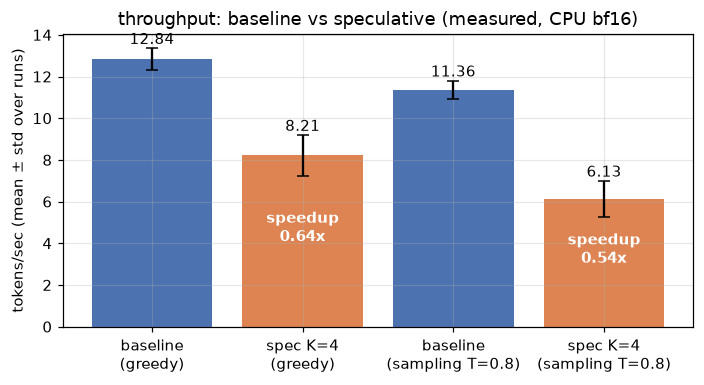

speedup < 1 means speculative decoding is SLOWER on this hardware:
  greedy            : 0.64x
  sampling T=0.8    : 0.54x


In [3]:
def tps(df, mode):
    d = df[df["mode"] == mode]
    return d["tokens_per_sec"].mean(), d["tokens_per_sec"].std()

groups = [("greedy", expA_g), ("sampling T=0.8", expA_s)]
labels, means, stds, speedups = [], [], [], []
for name, df in groups:
    b, bs = tps(df, "baseline")
    s, ss = tps(df, "speculative")
    labels += [f"baseline\n({name})", f"spec K=4\n({name})"]
    means += [b, s]
    stds += [bs, ss]
    speedups.append(s / b)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(labels, means, yerr=stds, capsize=4,
              color=["#4c72b0", "#dd8452"] * 2)
for i, v in enumerate(means):
    ax.text(i, v + stds[i] + 0.2, f"{v:.2f}", ha="center")
for j, sp in enumerate(speedups):
    ax.text(1 + 2 * j, means[1 + 2 * j] / 2, f"speedup\n{sp:.2f}x", ha="center",
            color="white", fontweight="bold")
ax.set_ylabel("tokens/sec (mean ± std over runs)")
ax.set_title("throughput: baseline vs speculative (measured, CPU bf16)")
fig.tight_layout()
save_fig(fig, "fig04_throughput.png")
plt.show()

print("speedup < 1 means speculative decoding is SLOWER on this hardware:")
for (name, _), sp in zip(groups, speedups):
    print(f"  {name:18s}: {sp:.2f}x")

## Latency: p50 / p95 and time-to-first-token

saved reports/figures/fig04_latency.png


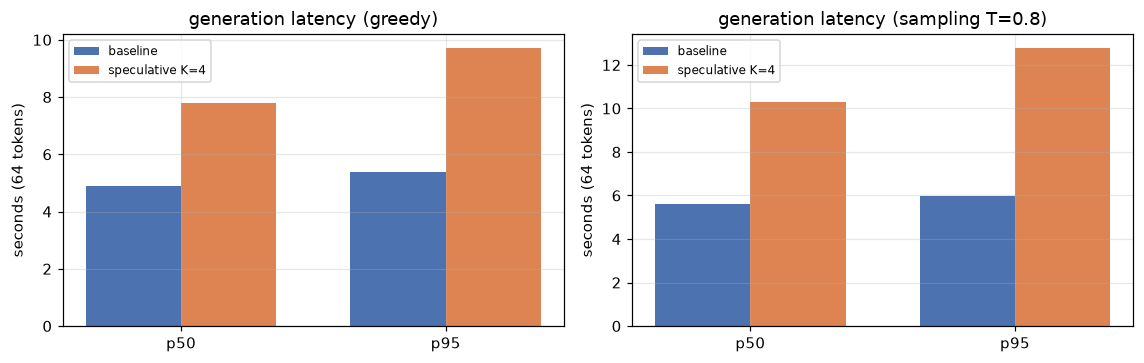

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
for ax, (name, df) in zip(axes, groups):
    b = df[df["mode"] == "baseline"]
    s = df[df["mode"] == "speculative"]
    x = np.arange(2)
    ax.bar(x - 0.18, [b["wall_time"].quantile(0.5), b["wall_time"].quantile(0.95)],
           width=0.36, label="baseline", color="#4c72b0")
    ax.bar(x + 0.18, [s["wall_time"].quantile(0.5), s["wall_time"].quantile(0.95)],
           width=0.36, label="speculative K=4", color="#dd8452")
    ax.set_xticks(x, ["p50", "p95"])
    ax.set_ylabel("seconds (64 tokens)")
    ax.set_title(f"generation latency ({name})")
    ax.legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "fig04_latency.png")
plt.show()

saved reports/figures/fig04_ttft.png


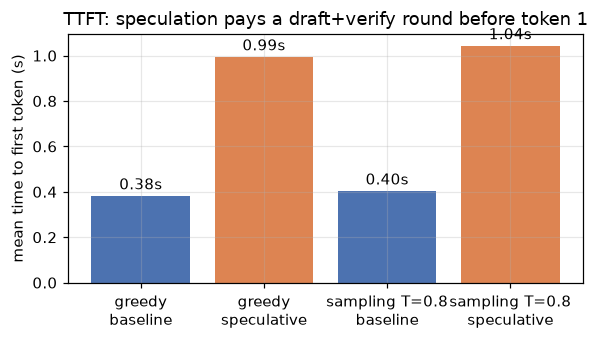

In [5]:
ttft = {}
for name, df in groups:
    for mode in ["baseline", "speculative"]:
        ttft[(name, mode)] = df[df["mode"] == mode]["ttft"].mean()

fig, ax = plt.subplots(figsize=(5.5, 3.2))
labels = [f"{n}\n{m}" for (n, m) in ttft]
ax.bar(labels, list(ttft.values()),
       color=["#4c72b0", "#dd8452", "#4c72b0", "#dd8452"])
ax.set_ylabel("mean time to first token (s)")
ax.set_title("TTFT: speculation pays a draft+verify round before token 1")
for i, v in enumerate(ttft.values()):
    ax.text(i, v + 0.03, f"{v:.2f}s", ha="center")
fig.tight_layout()
save_fig(fig, "fig04_ttft.png")
plt.show()

## Effect of K (draft length)

Three quantities per K, all measured: throughput, p50 latency, and tokens committed
per target forward (round yield) with the token-level acceptance rate.

saved reports/figures/fig04_k_sweep.png


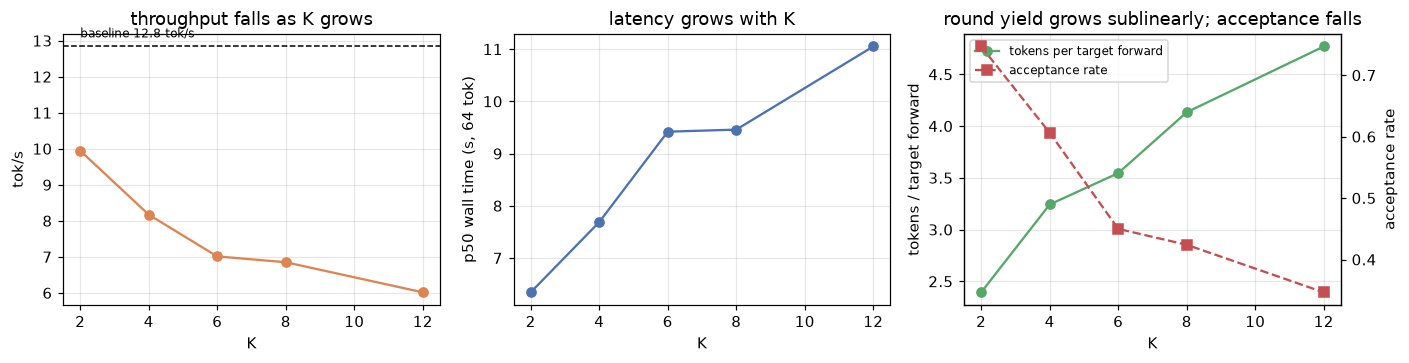

K= 2:  9.95 tok/s (0.77x baseline) | p50  6.34s | tok/fwd 2.39 | acc 0.747
K= 4:  8.17 tok/s (0.64x baseline) | p50  7.69s | tok/fwd 3.24 | acc 0.606
K= 6:  7.01 tok/s (0.55x baseline) | p50  9.42s | tok/fwd 3.55 | acc 0.450
K= 8:  6.85 tok/s (0.53x baseline) | p50  9.46s | tok/fwd 4.13 | acc 0.424
K=12:  6.01 tok/s (0.47x baseline) | p50 11.05s | tok/fwd 4.77 | acc 0.347


In [6]:
ks = sorted(int(k) for k in expB["K"].unique())
base_tps = expA_g[expA_g["mode"] == "baseline"]["tokens_per_sec"].mean()

agg = {}
for K in ks:
    d = expB[expB["K"] == K]
    agg[K] = {
        "tps": d["tokens_per_sec"].mean(),
        "p50": d["wall_time"].quantile(0.5),
        "tpf": d["mean_tokens_per_target_forward"].mean(),
        "acc": d["accepted"].sum() / d["proposed"].sum(),
    }

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
axes[0].plot(ks, [agg[k]["tps"] for k in ks], "o-", color="#dd8452")
axes[0].axhline(base_tps, color="k", ls="--", lw=1)
axes[0].text(ks[0], base_tps + 0.25, f"baseline {base_tps:.1f} tok/s", fontsize=8)
axes[0].set_xlabel("K"); axes[0].set_ylabel("tok/s")
axes[0].set_title("throughput falls as K grows")

axes[1].plot(ks, [agg[k]["p50"] for k in ks], "o-", color="#4c72b0")
axes[1].set_xlabel("K"); axes[1].set_ylabel("p50 wall time (s, 64 tok)")
axes[1].set_title("latency grows with K")

ax2 = axes[2]
ax2.plot(ks, [agg[k]["tpf"] for k in ks], "o-", color="#55a868", label="tokens per target forward")
ax2.set_xlabel("K"); ax2.set_ylabel("tokens / target forward")
ax3 = ax2.twinx()
ax3.plot(ks, [agg[k]["acc"] for k in ks], "s--", color="#c44e52", label="acceptance rate")
ax3.set_ylabel("acceptance rate")
ax3.grid(False)
ax2.set_title("round yield grows sublinearly; acceptance falls")
lines = ax2.get_lines() + ax3.get_lines()
ax2.legend(lines, [l.get_label() for l in lines], fontsize=8)
fig.tight_layout()
save_fig(fig, "fig04_k_sweep.png")
plt.show()

for K in ks:
    print(f"K={K:2d}: {agg[K]['tps']:5.2f} tok/s ({agg[K]['tps']/base_tps:.2f}x baseline) | "
          f"p50 {agg[K]['p50']:5.2f}s | tok/fwd {agg[K]['tpf']:.2f} | acc {agg[K]['acc']:.3f}")

## Per-prompt variation

Same K, same models — the speedup still varies by prompt because acceptance does. Bars: per-prompt speedup (baseline wall / spec wall); line: acceptance rate.

saved reports/figures/fig04_per_prompt.png


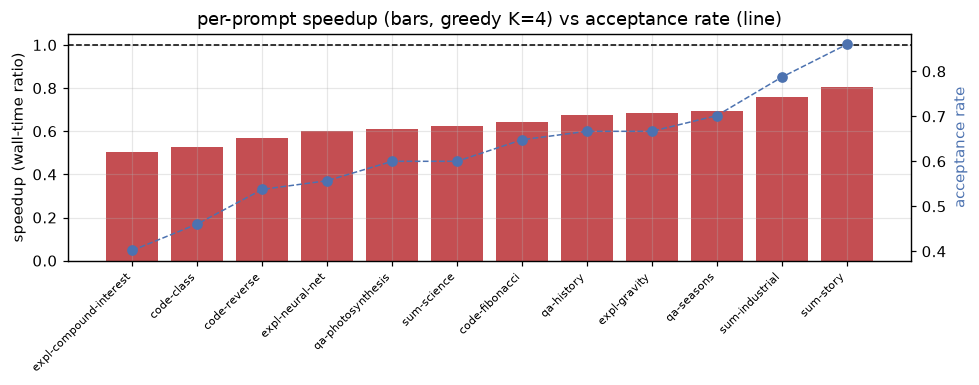

best prompt : sum-story (0.81x, acc 0.86)
worst prompt: expl-compound-interest (0.51x, acc 0.40)


In [7]:
b = expA_g[expA_g["mode"] == "baseline"].groupby("prompt_id")["wall_time"].mean()
s = expA_g[expA_g["mode"] == "speculative"]
sp = s.groupby("prompt_id")["wall_time"].mean()
acc = {pid: d["accepted"].sum() / d["proposed"].sum() for pid, d in s.groupby("prompt_id")}

speed = (b / sp).sort_values()
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = ["#55a868" if v >= 1 else "#c44e52" for v in speed.values]
ax.bar(range(len(speed)), speed.values, color=colors)
ax.axhline(1.0, color="k", ls="--", lw=1)
ax.set_xticks(range(len(speed)))
ax.set_xticklabels(speed.index, rotation=45, ha="right", fontsize=7)
ax.set_ylabel("speedup (wall-time ratio)")
ax2 = ax.twinx()
ax2.plot(range(len(speed)), [acc[p] for p in speed.index], "o--", color="#4c72b0", lw=1)
ax2.set_ylabel("acceptance rate", color="#4c72b0")
ax2.grid(False)
ax.set_title("per-prompt speedup (bars, greedy K=4) vs acceptance rate (line)")
fig.tight_layout()
save_fig(fig, "fig04_per_prompt.png")
plt.show()
print(f"best prompt : {speed.index[-1]} ({speed.iloc[-1]:.2f}x, acc {acc[speed.index[-1]]:.2f})")
print(f"worst prompt: {speed.index[0]} ({speed.iloc[0]:.2f}x, acc {acc[speed.index[0]]:.2f})")

## Conclusions (from the measurements above)

1. **No configuration beat the baseline on this CPU.** Best measured point: K=2 greedy
   (≈0.77× baseline); the default K=4 lands at ≈0.64× greedy / ≈0.54× sampling.
2. **Throughput decreases monotonically with K** here (K=2 → K=12), while the round
   yield (tokens per target forward) grows only sublinearly — the extra draft steps and
   the longer verification pass cost more than the extra accepted tokens return.
3. **Per-prompt speedup tracks acceptance**: the best/worst prompts above differ by
   acceptance rate, not by length.
4. **TTFT is worse under speculation**: the first token waits for a full
   draft-K + verify round.
5. These are *hardware-regime* results, not algorithm results: the acceptance behavior
   (≈0.6 greedy) is exactly what makes published GPU speedups work. Notebook 05
   measures the cost structure that flips the sign.